# Lab 9&10: PCA Analysis
## With Hypoxia Data

------



Lab TA: Lee Ochs

## Lab Objectives:

1. Data visualization 
2. Prepare data for PCA 
3. Interpret PCA results
4. Perform some ANOVA analysis for the PCA results

In [2]:
#load the correct environment/kernel (python 3 ipykernel)
#mine uses the base enviornment 
#if package does not load correctly, close notebook, type "conda activate base" in ur terminal, then type "jupyter notebook"
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [42]:
lab10_observation = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab10\Lab10_observations_gulf_final.csv')

lab10_observation.head()

,sal,oxy,nit,sil,seat,pho,olat,olon,odate,sdep,bdep
0,20.1993,4.573,4.08,9.00,21.4497,0.49,29.1209,-91.9110,2004-04-03 15:05:00.000002,4.2,10.2
1,29.5492,4.248,2.72,6.69,21.3889,0.49,29.1209,-91.9110,2004-04-03 15:05:00.000002,4.9,10.2
2,30.1078,0.350,1.79,12.18,21.3224,0.34,29.1209,-91.9110,2004-04-03 15:05:00.000002,9.5,10.2
3,28.1494,5.961,1.47,1.48,21.7144,0.40,28.9984,-92.0039,2004-04-03 16:49:59.999999,2.1,19.8
4,29.0810,5.841,8.66,11.44,21.6544,1.32,28.9984,-92.0039,2004-04-03 16:49:59.999999,2.2,19.8


<Axes: xlabel='nit', ylabel='sal'>

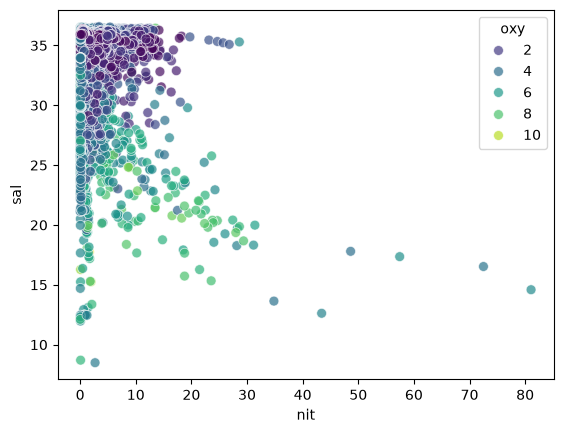

In [7]:
#data investigation

#what make oxygen low? fresh water and nitrate?
#let's plot nitrate vs salinity, color coded by oxygen concentration
#practise: run the code, and uncomment options at a time to see how the plot changes
sns.scatterplot(
    data=lab10_observation,
    x='nit',
    y='sal',
    hue='oxy',palette='viridis', #hue is for color coding and chose the right color map
    s=50,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)


#what do you see with the color coding?
#it seems that low oxgen is actually associated with high salinity (opposite of freshwater), even at lower nitrate concentration
#does it make sense?(hint: bottom oxygen depletion)

#we are getting close but this is not descriptive enough



<Axes: xlabel='sal', ylabel='seat'>

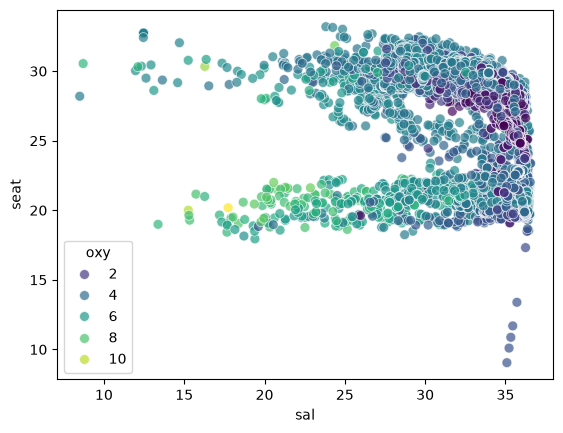

In [6]:
sns.scatterplot(
    data=lab10_observation,
    x='sal',
    y='seat',
    hue='oxy',palette='viridis', #hue is for color coding and chose the right color map
    s=50,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)

#high sal and high temp
#what does that mean in oceanography sense?
#talk about thermocline, halocline and oxygen minimum zone
#scale of meters and shelf area

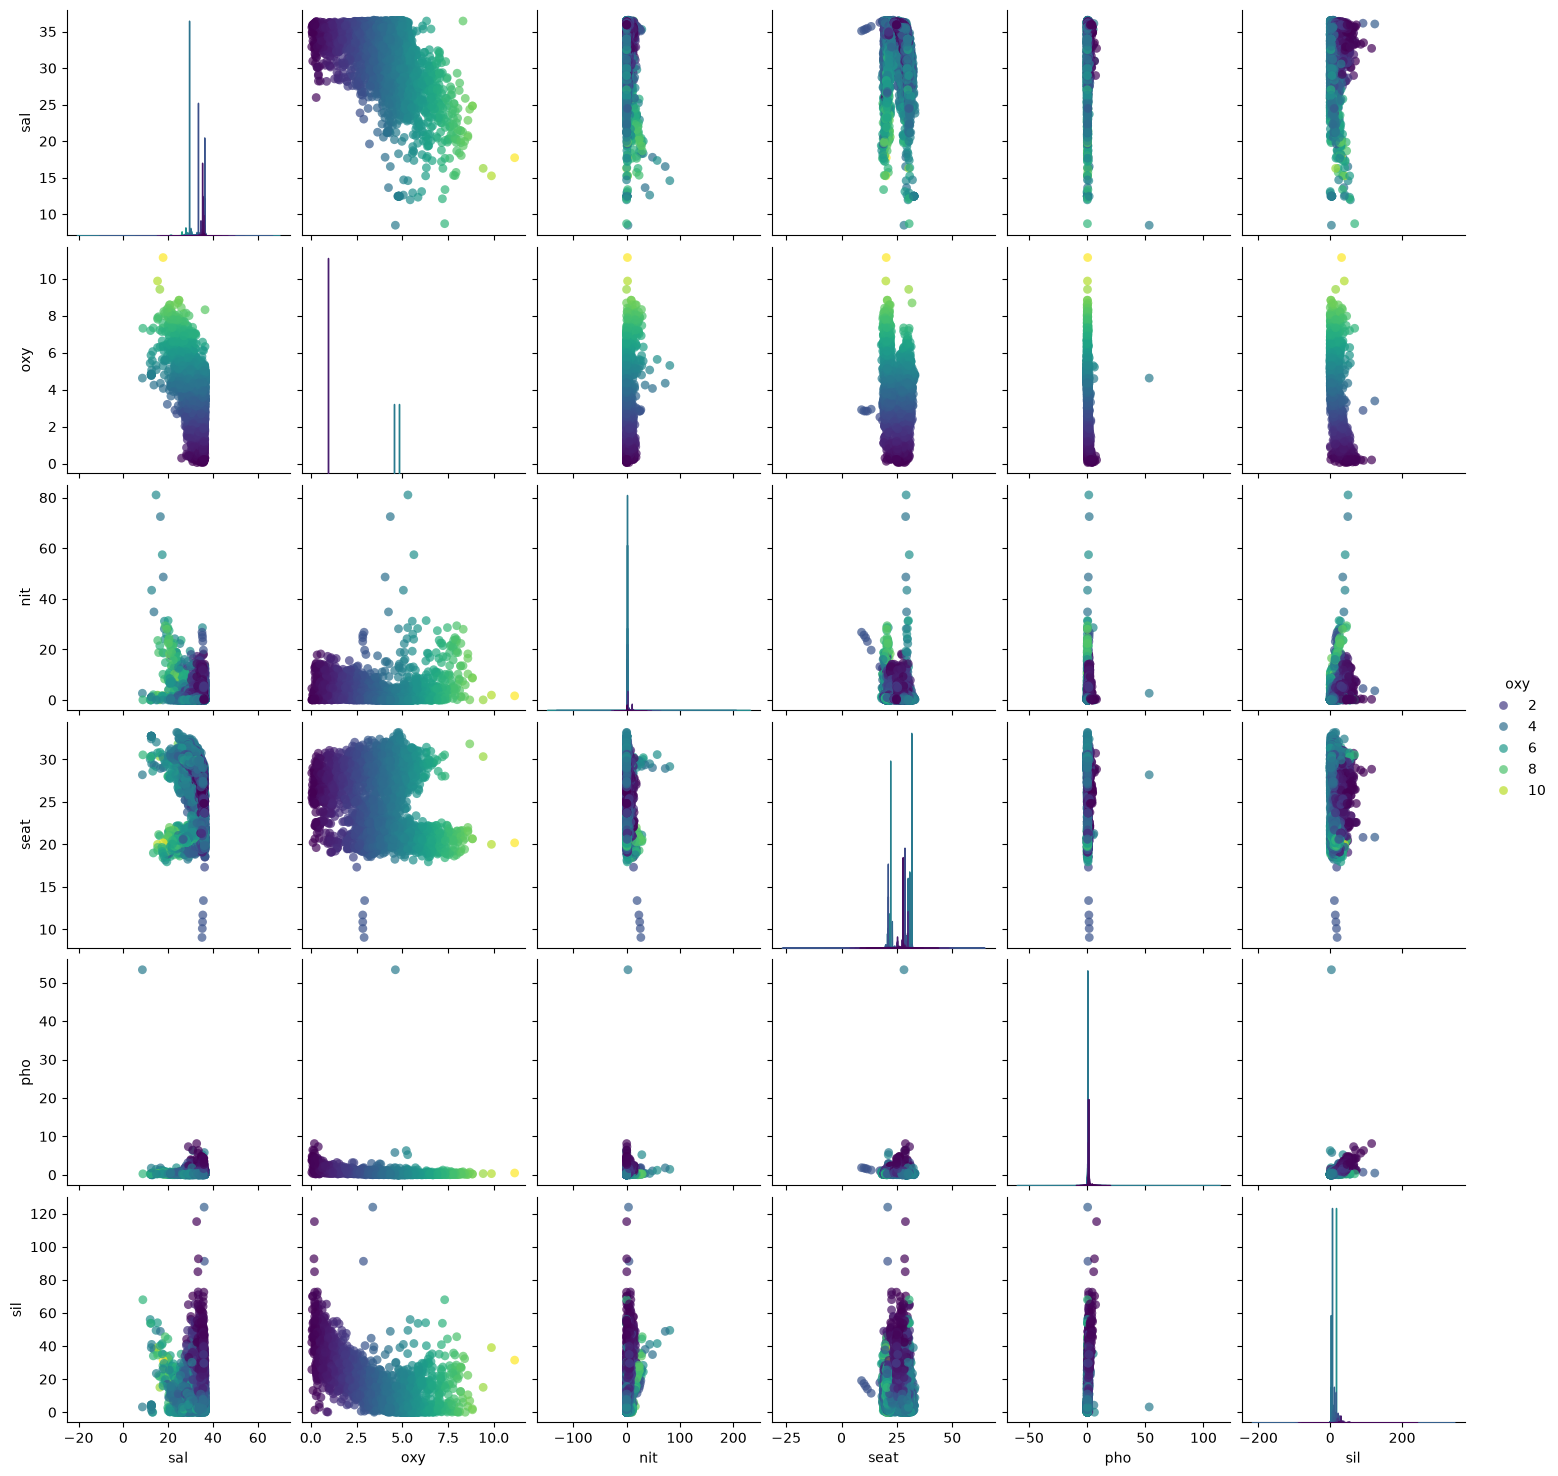

In [41]:
#lets check all the variables
pca_data = lab10_observation[['sal','oxy','nit','sil','seat','pho']]

#there is a easier way to visualize the relationships among multiple variables
#change the hue to oxy and other variables to see any trends
sns.pairplot(
    pca_data,
    vars=['sal', 'oxy', 'nit', 'seat', 'pho','sil'],
    hue='oxy',
    palette='viridis',
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 40, 'edgecolor': 'none'},
    diag_kws={'color': 'black'}  #
)

plt.show()

However, it still difficult to have a conlusion
There are too many dimension of data for us to just eyeball it.
Lets do PCA

Prepare the data
- Delete NA
- Scale/normalize data

In [46]:
#check na
pca_data.isna()
pca_data.isna().sum()

sal     0
oxy     0
nit     0
sil     0
seat    0
pho     0
dtype: int64

In [45]:
#get rid of na
pca_data= pca_data.dropna()
pca_data.isna().sum()

sal     0
oxy     0
nit     0
sil     0
seat    0
pho     0
dtype: int64

In [11]:
#normalize the data

from sklearn.preprocessing import StandardScaler
#sklearn is a machine learning package in python


scaler = StandardScaler()

pca_data_scaled = scaler.fit_transform(pca_data)

#it will scale the data to have mean 0 and standard deviation 1
#so it calculate the mean first and then subtract the mean from each data
#then divide the standard deviation


Why do we normalize the data?
Lets visualize.

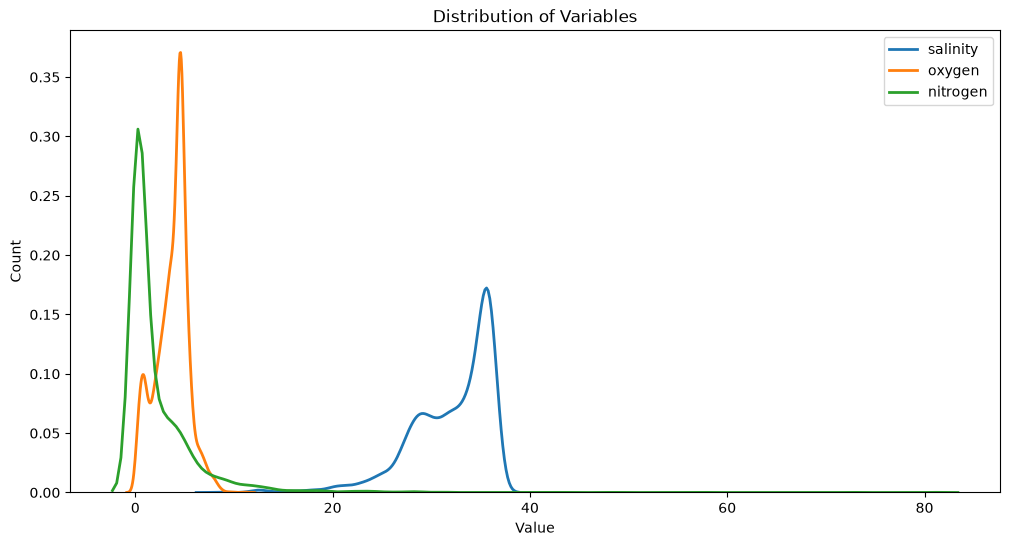

In [47]:
#practise, plot sal, oxy, and nit distributions before scaling
#Use seaborn's histplot with multiple variables

plt.figure(figsize=(12,6))
sns.kdeplot(pca_data['sal'], label="salinity", linewidth=2)
sns.kdeplot(pca_data['oxy'], label="oxygen", linewidth=2)
sns.kdeplot(pca_data['nit'], label="nitrogen", linewidth=2)
plt.title("Distribution of Variables")
plt.xlabel("Value")
plt.ylabel("Count")
plt.legend()
plt.show()

In [15]:
#pca_data_scaled is a matrix/np array, 
#so convert it back to dataframe for easier plotting and bind the column names

features = ['sal','oxy','nit','sil','seat','pho']

scaled_df = pd.DataFrame(pca_data_scaled, columns=features)

scaled_df.head()


,sal,oxy,nit,sil,seat,pho
0,-2.868185,0.489540,0.447879,-0.314000,-1.138505,-0.024388
1,-0.609675,0.291566,0.118822,-0.490549,-1.153440,-0.024388
2,-0.474743,-2.082908,-0.106195,-0.070958,-1.169775,-0.177925
3,-0.947803,1.335043,-0.183621,-0.888741,-1.073483,-0.116510
4,-0.722771,1.261945,1.556028,-0.127515,-1.088222,0.825188


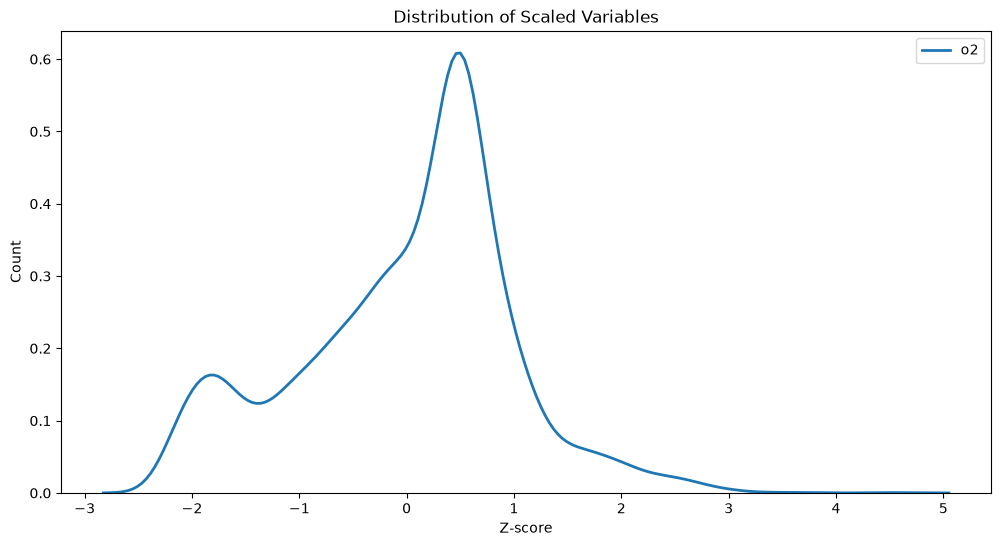

In [16]:
#now plot distributions for scaled data
#lets try sal, oxy, and nit distributions after scaling

# Plot distributions for scaled data
plt.figure(figsize=(12,6))
sns.kdeplot(scaled_df['oxy'], label="o2", linewidth=2)

plt.title("Distribution of Scaled Variables")
plt.xlabel("Z-score")
plt.ylabel("Count")
plt.legend()
plt.show()

#what do you see (shape, center, spread)?

In [17]:
#perform PCA analysis with the scaled data
from sklearn.decomposition import PCA

#these few lines of code run the PCA and save the results
pca = PCA() # initilize a PCA model, now it is empty, we did not specify number of componets, so it will keep all components by default
data_pcaed = pca.fit_transform(pca_data_scaled)  #the new data but in the PCA space
coeff = pca.components_           # (loadings)
latent = pca.explained_variance_    #
explained_var_ratio = pca.explained_variance_ratio_  # variance %

All the data returned are matrix without column names
- it is easier to add the names back

In [18]:

data_pcaed.shape
#it has 6 PCs, PC1 to PC6

(4359, 6)

In [20]:
#practise save it as dataframe with column names PC1 through PC6
df_pca = pd.DataFrame(
    data_pcaed,
    columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']
)

df_pca.head()




,PC1,PC2,PC3,PC4,PC5,PC6
0,1.294179,2.213081,0.455327,0.463643,1.148371,-1.322289
1,0.550759,0.780051,-0.689089,0.493633,0.232432,-0.598443
2,-1.007223,-0.105165,-0.554566,-0.137624,0.717011,-2.028320
3,1.619741,0.939516,-0.621851,0.826301,0.256515,-0.169303
4,0.286680,2.294247,-0.368762,0.736938,-0.582042,0.232287


In [21]:
#i am also gonna bind it to the orginal data for easier plotting
#use pd.concat for 
df_combined = pd.concat([df_pca, pca_data.reset_index(drop=True)], axis=1)

#rest index is true because we dropped some row with na values earlier, so the index was different for the original data

In [48]:
df_combined.head()
#df_combined['PC1']

,PC1,PC2,PC3,PC4,PC5,PC6,sal,oxy,nit,sil,seat,pho,date,month
0,1.294179,2.213081,0.455327,0.463643,1.148371,-1.322289,20.1993,4.573,4.08,9.00,21.4497,0.49,2004-04-03 15:05:00.000002,4
1,0.550759,0.780051,-0.689089,0.493633,0.232432,-0.598443,29.5492,4.248,2.72,6.69,21.3889,0.49,2004-04-03 15:05:00.000002,4
2,-1.007223,-0.105165,-0.554566,-0.137624,0.717011,-2.028320,30.1078,0.350,1.79,12.18,21.3224,0.34,2004-04-03 15:05:00.000002,4
3,1.619741,0.939516,-0.621851,0.826301,0.256515,-0.169303,28.1494,5.961,1.47,1.48,21.7144,0.40,2004-04-03 16:49:59.999999,4
4,0.286680,2.294247,-0.368762,0.736938,-0.582042,0.232287,29.0810,5.841,8.66,11.44,21.6544,1.32,2004-04-03 16:49:59.999999,4


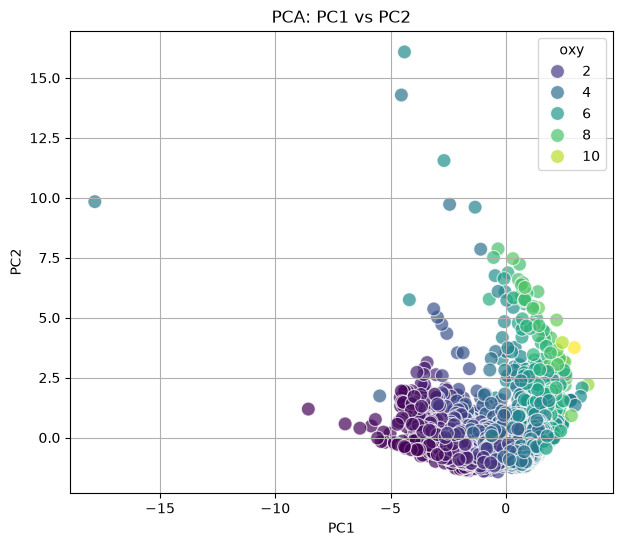

In [30]:
#lets plot PC1 vs PC2, color it by oxygen
plt.figure(figsize=(7,6))
sns.scatterplot(
    data = df_combined,
    x='PC1',
    y='PC2',
    hue='oxy',palette='viridis', #hue is for color coding and chose the right color map
    s=100,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: PC1 vs PC2')
plt.grid(True)
plt.show()

#trends of oxygen now becomes more clear
#but what does PC1 and PC2 mean?

What does PC1 and PC2 mean?
Does it make sense to use PC1 and PC2, what about PC3 and PC4

Loading/coefficients
$$
\text{PC}_1 = a_1 x_1 + a_2 x_2 + \dots + a_n x_n
$$


In [31]:
#check the loading/coefficients
coeff
#it is a 6 by 6 matrix, 6 rows for 6 PCs and 6 columns for 6 original variables
#lets save it to a df


array([[-0.35699626,  0.58199457, -0.23948955, -0.56939497,  0.08386784,
        -0.38109881],
       [-0.49346612,  0.30575909,  0.69874439,  0.18854216, -0.34914637,
         0.13155801],
       [-0.50331689, -0.08876799, -0.02413944,  0.12203896,  0.7794371 ,
         0.34028509],
       [-0.04090647,  0.22293323, -0.40229607, -0.16471736, -0.33836333,
         0.80322087],
       [-0.44435535, -0.05349136, -0.53990398,  0.59375005, -0.28247187,
        -0.27542915],
       [ 0.42022845,  0.71228744, -0.02190644,  0.49565793,  0.26317428,
         0.02524417]])

In [32]:
loadings = pd.DataFrame(
    pca.components_,
    columns=features
)
#create a new column for PC names
#they are in order from 1 to 6
loadings['PC'] = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']
print(loadings)




        sal       oxy       nit       sil      seat       pho   PC
0 -0.356996  0.581995 -0.239490 -0.569395  0.083868 -0.381099  PC1
1 -0.493466  0.305759  0.698744  0.188542 -0.349146  0.131558  PC2
2 -0.503317 -0.088768 -0.024139  0.122039  0.779437  0.340285  PC3
3 -0.040906  0.222933 -0.402296 -0.164717 -0.338363  0.803221  PC4
4 -0.444355 -0.053491 -0.539904  0.593750 -0.282472 -0.275429  PC5
5  0.420228  0.712287 -0.021906  0.495658  0.263174  0.025244  PC6


looking at the df_combined, each row under PC1 is all the data calculated using below coefficents
- it is a linear combination of all original variables weighted by the coefficents
- In PC1, oxy and sil are the most important 
- Are PC1 and PC2 enough to explain all the variablity?

In [33]:
explained_var_ratio = pca.explained_variance_ratio_  # variance %

explained_var_ratio



array([0.37638854, 0.21256706, 0.19177837, 0.12500974, 0.07183599,
       0.0224203 ])

In [35]:
#create a new column in the loading to save the explained variance 
loadings['Explained_Var_Ratio'] = explained_var_ratio

loadings.head()


,sal,oxy,nit,sil,seat,pho,PC,Explained_Var_Ratio
0,-0.356996,0.581995,-0.239490,-0.569395,0.083868,-0.381099,PC1,0.376389
1,-0.493466,0.305759,0.698744,0.188542,-0.349146,0.131558,PC2,0.212567
2,-0.503317,-0.088768,-0.024139,0.122039,0.779437,0.340285,PC3,0.191778
3,-0.040906,0.222933,-0.402296,-0.164717,-0.338363,0.803221,PC4,0.125010
4,-0.444355,-0.053491,-0.539904,0.593750,-0.282472,-0.275429,PC5,0.071836


<Axes: xlabel='PC', ylabel='Explained_Var_Ratio'>

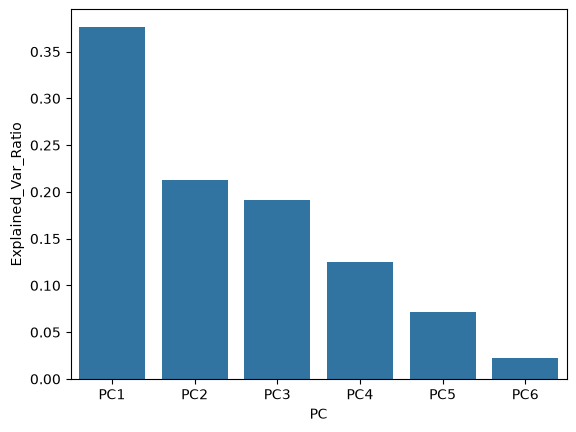

In [36]:
sns.barplot(data = loadings, x='PC', y='Explained_Var_Ratio')



In [37]:
#this is indivial, lets calculate cumulative
loadings['Cumulative_Explained_Var'] = loadings['Explained_Var_Ratio'].cumsum()

<Axes: xlabel='PC', ylabel='Cumulative_Explained_Var'>

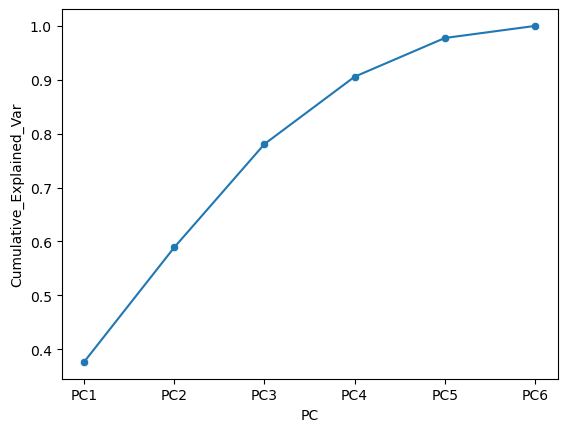

In [ ]:
#practise plot cumulative explained variance with scatter and line plot from sns in one figure


#seems pc 1 and pc2 are good for most?
#PC3 is similar to pc2 tho

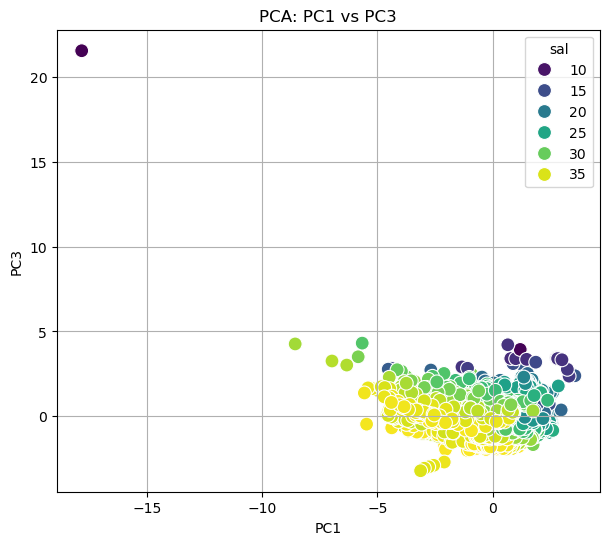

In [ ]:

#lets plot that color it with different variables
#practise plot PC1 vs PC3, color it by salinity or oxygen to see
plt.figure(figsize=(7,6))
sns.scatterplot(
    data = df_combined,
    s=100
)
plt.xlabel('PC1')
plt.ylabel('PC3')
plt.title('PCA: PC1 vs PC3')
plt.grid(True)
plt.show()



Finally, time series analysis of the different components
Is hypoxia seasonal?
Plot PC3 vs Month

In [38]:
df_combined['date'] = lab10_observation['odate'].reset_index(drop=True)

In [39]:
df_combined['date']
#extract the month
df_combined['date'] = pd.to_datetime(df_combined['date'])
df_combined['month'] = df_combined['date'].dt.month



In [50]:
df_combined.head()

,PC1,PC2,PC3,PC4,PC5,PC6,sal,oxy,nit,sil,seat,pho,date,month
0,1.294179,2.213081,0.455327,0.463643,1.148371,-1.322289,20.1993,4.573,4.08,9.00,21.4497,0.49,2004-04-03 15:05:00.000002,4
1,0.550759,0.780051,-0.689089,0.493633,0.232432,-0.598443,29.5492,4.248,2.72,6.69,21.3889,0.49,2004-04-03 15:05:00.000002,4
2,-1.007223,-0.105165,-0.554566,-0.137624,0.717011,-2.028320,30.1078,0.350,1.79,12.18,21.3224,0.34,2004-04-03 15:05:00.000002,4
3,1.619741,0.939516,-0.621851,0.826301,0.256515,-0.169303,28.1494,5.961,1.47,1.48,21.7144,0.40,2004-04-03 16:49:59.999999,4
4,0.286680,2.294247,-0.368762,0.736938,-0.582042,0.232287,29.0810,5.841,8.66,11.44,21.6544,1.32,2004-04-03 16:49:59.999999,4


<Axes: xlabel='month', ylabel='PC3'>

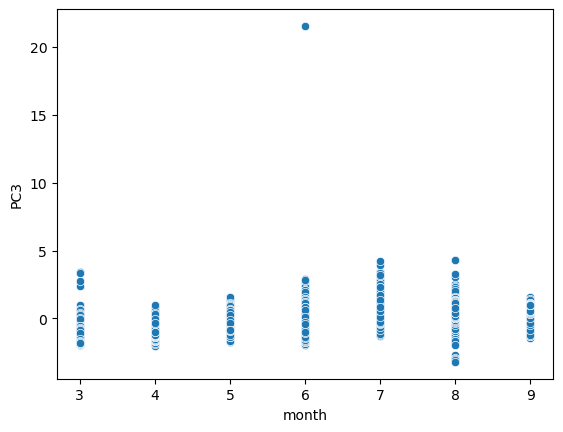

In [ ]:
#practise, plot pc3 vs month with bar plot or scatter plot


In [ ]:
#you need to do ANOVA analysis for the different months to see if there is significant seasonal variability
#hint: you would need to extract the data for each month and pc3, 
#then run a tukey's test to see which months are significantly different from each other
#see the code from anova labs